# NB 09 (Appendix) — BTO hybrid dataset: a preserved negative result

> **internal-consistency illustration only; the underlying data are a Cochran-calibrated phenomenological reconstruction, not first-principles SCPH frequencies; this appendix demonstrates why the data cannot validate any soft-mode theory and motivates the literature-benchmark approach of §3.2–§3.4.**

Reproduces the aborted Turn-4 scalar-SCPH calibration against the old `data/raw/BTO/` hybrid CSVs (loaded **unchanged**): the SCPH-vs-data residual $\delta$ blows up to **+2806% at 400 K**. The arithmetic was correct (SCPH converges, $\Omega^2>0$); the failure is *structural* — the Ehsan first-principles $q{=}0$ SCPH curve and the hybrid $q{=}0.1$ reconstruction are incommensurate. Reinforced by the Turn-4B finding that BTO's soft mode is genuinely **overdamped** ($\eta_{\rm BTO}\approx2.27$, HAS 1971), so the data lie outside the underdamped-quasiparticle framework entirely — not merely poorly-fit.


In [1]:
import sys
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    return start

PROJECT_ROOT = _find_project_root(Path.cwd())
SRC = PROJECT_ROOT / "src"
if SRC.exists() and str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
# Preserved pre-revert scalar-SCPH code (the exact Turn-4 aborted calibration):
ARCHIVE = PROJECT_ROOT / "archive" / "scph_calibration"
if str(ARCHIVE) not in sys.path:
    sys.path.insert(0, str(ARCHIVE))
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)

from fekappa.plots import set_publication_style
import scph_calibration_snapshot as scph_old   # calibrate_A_from_ehsan, scph_iterate, scph_curve
set_publication_style()

# The disclaimer that labels EVERY figure and result in this appendix:
DISCLAIMER = ("internal-consistency illustration only -- the underlying data are a "
    "Cochran-calibrated phenomenological reconstruction, NOT first-principles SCPH "
    "frequencies. This appendix shows why the data cannot validate any soft-mode "
    "theory; it motivates the literature-benchmark approach of sec. 3.2-3.4.")
def stamp(fig):
    """Stamp the disclaimer on every figure in this negative-result appendix."""
    fig.text(0.5, -0.04, DISCLAIMER, ha="center", va="top", fontsize=6.5,
             style="italic", color="0.3", wrap=True)

FLAGS = []
def flag(item, ok, note=""):
    print(f"  [{'OK ' if ok else 'STOP'}] {item}" + (f"  ({note})" if note else "")); FLAGS.append((item, ok, note))

print("PROJECT_ROOT:", PROJECT_ROOT)


PROJECT_ROOT: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph


## 1. The hybrid BTO CSVs, loaded unchanged

> **internal-consistency illustration only; the underlying data are a Cochran-calibrated phenomenological reconstruction, not first-principles SCPH frequencies; this appendix demonstrates why the data cannot validate any soft-mode theory and motivates the literature-benchmark approach of §3.2–§3.4.**


  T_K  omega_meV  gamma_hwhm_meV  omega_sq_meV2      eta
100.0       11.2            0.60         125.44 0.053571
200.0        9.8            0.75          96.04 0.076531
300.0        8.2            1.05          67.24 0.128049
400.0        3.5            1.80          12.25 0.514286
500.0        5.8            2.50          33.64 0.431034
600.0        6.5            3.00          42.25 0.461538
  [OK ] hybrid CSVs loaded unchanged  (6 temperatures 100-600 K)
  [OK ] soft mode non-monotonic (reconstruction artifact)  (dips to 3.5 meV at 400 K then recovers)


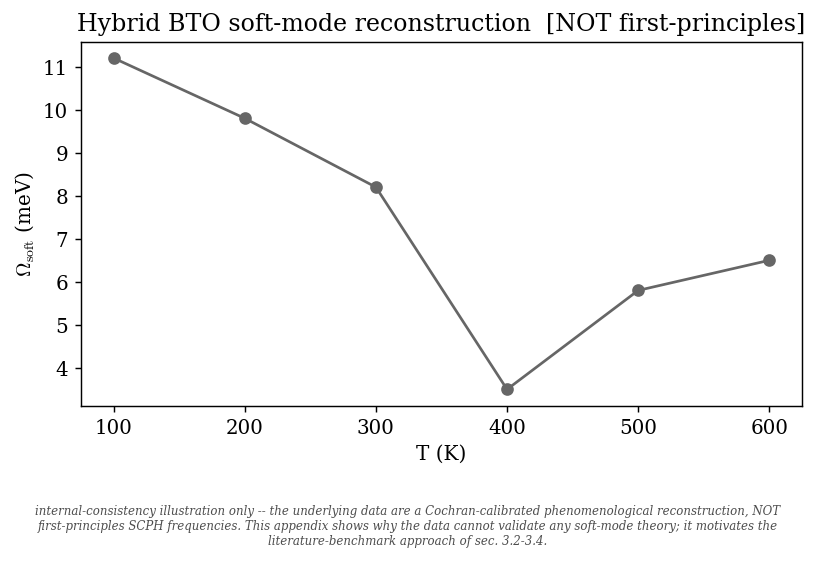

In [2]:
# Load the OLD hybrid BTO CSVs UNCHANGED (data/raw/BTO/phonon_modes_*K.csv).
rows = []
for f in sorted(glob.glob(str(PROJECT_ROOT / "data" / "raw" / "BTO" / "phonon_modes_*K.csv"))):
    d = pd.read_csv(f)
    so = d[d["mode_type"] == "polar_soft"].iloc[0]
    rows.append(dict(T_K=float(so["temperature_K"]), omega_meV=float(so["omega_Q_meV"]),
                     gamma_hwhm_meV=float(so["Gamma_Q_HWHM_meV"])))
hyb = pd.DataFrame(rows).sort_values("T_K").reset_index(drop=True)
hyb["omega_sq_meV2"] = hyb["omega_meV"] ** 2
hyb["eta"] = hyb["gamma_hwhm_meV"] / hyb["omega_meV"]
print(hyb.to_string(index=False))

flag("hybrid CSVs loaded unchanged", len(hyb) == 6, f"{len(hyb)} temperatures 100-600 K")
flag("soft mode non-monotonic (reconstruction artifact)",
     hyb["omega_meV"].iloc[3] < hyb["omega_meV"].iloc[2], "dips to 3.5 meV at 400 K then recovers")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(hyb["T_K"], hyb["omega_meV"], "-o", color="0.4")
ax.set_xlabel("T (K)"); ax.set_ylabel(r"$\Omega_{\rm soft}$ (meV)")
ax.set_title("Hybrid BTO soft-mode reconstruction  [NOT first-principles]")
stamp(fig); fig.tight_layout(); fig.savefig(FIG_DIR / "fig_NB09_hybrid_softmode.pdf", bbox_inches="tight")
plt.show()


## 2. Scalar-SCPH residual: $\delta\approx+2806\%$ at 400 K

> **internal-consistency illustration only; the underlying data are a Cochran-calibrated phenomenological reconstruction, not first-principles SCPH frequencies; this appendix demonstrates why the data cannot validate any soft-mode theory and motivates the literature-benchmark approach of §3.2–§3.4.**


Ehsan-calibrated A = 208.28 meV^2  (E0^2=-424.0, hbarOmega(500K)=21.08 meV)
  T_K  omega_sq_meV2  scph_sq_meV2  delta_pct
100.0          125.4          62.3      -50.4
200.0           96.0         163.3       70.0
300.0           67.2         262.4      290.3
400.0           12.2         356.0     2805.8
500.0           33.6         444.4     1220.9
600.0           42.2         528.4     1150.6

delta(400 K) = +2806%   (preserved negative result: +2806%)
  [OK ] SCPH converged at all T (arithmetic correct)  (the disagreement is structural, not a bug)
  [OK ] delta ~ +2806% at 400 K reproduced  (delta=+2806%)
  [OK ] residual blows up (data incommensurate w/ SCPH)  (Ehsan q=0 SCPH ~13x the hybrid q=0.1 reconstruction; Lambda^2 q^2 cannot bridge)


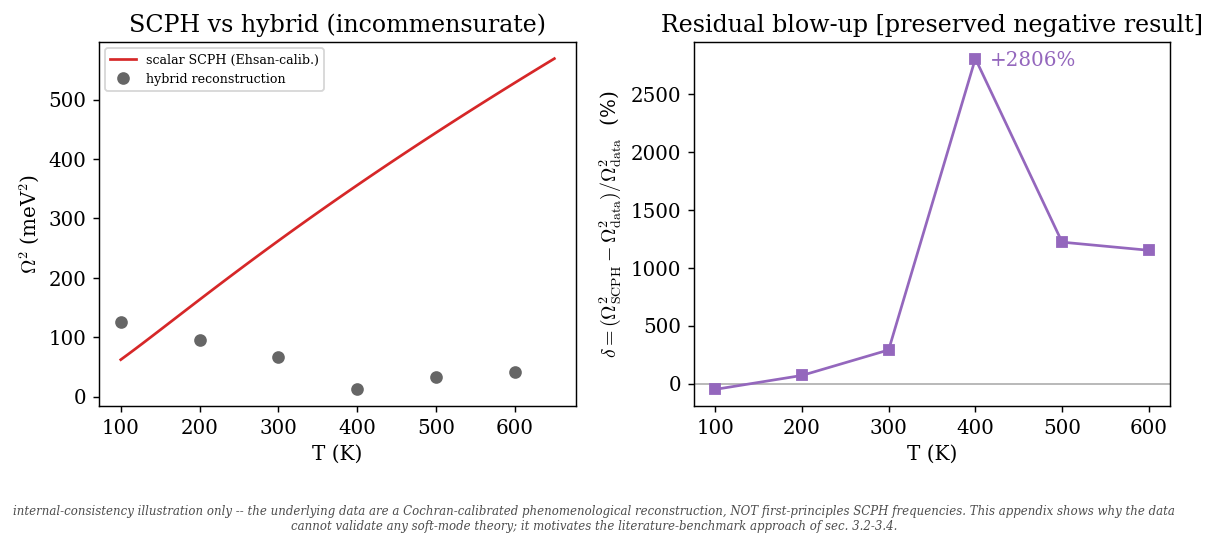

In [3]:
# Scalar SCPH (Ehsan 2021 two-anchor calibration), EXACT preserved code from the
# aborted Turn-4 attempt (archive/scph_calibration/scph_calibration_snapshot.py).
E0_SQ, E_ANCHOR, T_ANCHOR = -424.0, 21.08, 500.0
A = scph_old.calibrate_A_from_ehsan(E0_SQ, E_ANCHOR, T_ANCHOR)
print(f"Ehsan-calibrated A = {A:.2f} meV^2  (E0^2={E0_SQ}, hbarOmega(500K)={E_ANCHOR} meV)")

scph_sq, conv = [], []
for T in hyb["T_K"]:
    Es2, _, c = scph_old.scph_iterate(E0_SQ, A, float(T))
    scph_sq.append(Es2); conv.append(c)
hyb["scph_sq_meV2"] = scph_sq
hyb["delta_pct"] = (hyb["scph_sq_meV2"] - hyb["omega_sq_meV2"]) / hyb["omega_sq_meV2"] * 100.0
print(hyb[["T_K", "omega_sq_meV2", "scph_sq_meV2", "delta_pct"]].round(1).to_string(index=False))

d400 = float(hyb.loc[hyb["T_K"] == 400, "delta_pct"].iloc[0])
print(f"\ndelta(400 K) = {d400:+.0f}%   (preserved negative result: +2806%)")
flag("SCPH converged at all T (arithmetic correct)", all(conv), "the disagreement is structural, not a bug")
flag("delta ~ +2806% at 400 K reproduced", abs(d400 - 2806) < 30, f"delta={d400:+.0f}%")
flag("residual blows up (data incommensurate w/ SCPH)", hyb["delta_pct"].max() > 1000,
     "Ehsan q=0 SCPH ~13x the hybrid q=0.1 reconstruction; Lambda^2 q^2 cannot bridge")

# dense SCPH curve for the overlay
Tg = np.linspace(100, 650, 60)
curve = scph_old.scph_curve(Tg, E0_SQ, A)
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
ax = axes[0]
ax.plot(Tg, curve["E_sq_meV2"], "-", color="tab:red", label="scalar SCPH (Ehsan-calib.)")
ax.plot(hyb["T_K"], hyb["omega_sq_meV2"], "o", color="0.4", label="hybrid reconstruction")
ax.set_xlabel("T (K)"); ax.set_ylabel(r"$\Omega^2$ (meV$^2$)"); ax.legend(fontsize=7)
ax.set_title("SCPH vs hybrid (incommensurate)")
ax = axes[1]
ax.axhline(0, color="0.7", lw=1)
ax.plot(hyb["T_K"], hyb["delta_pct"], "-s", color="tab:purple")
ax.annotate(f"+{d400:.0f}%", (400, d400), xytext=(8, -4), textcoords="offset points", color="tab:purple")
ax.set_xlabel("T (K)"); ax.set_ylabel(r"$\delta = (\Omega^2_{\rm SCPH}-\Omega^2_{\rm data})/\Omega^2_{\rm data}$  (%)")
ax.set_title("Residual blow-up [preserved negative result]")
stamp(fig); fig.tight_layout(); fig.savefig(FIG_DIR / "fig_NB09_scph_residual.pdf", bbox_inches="tight")
plt.show()


## 3. Why it is structural: BTO is overdamped

> **internal-consistency illustration only; the underlying data are a Cochran-calibrated phenomenological reconstruction, not first-principles SCPH frequencies; this appendix demonstrates why the data cannot validate any soft-mode theory and motivates the literature-benchmark approach of §3.2–§3.4.**


  T_K  omega_meV  gamma_hwhm_meV   eta
100.0       11.2            0.60 0.054
200.0        9.8            0.75 0.077
300.0        8.2            1.05 0.128
400.0        3.5            1.80 0.514
500.0        5.8            2.50 0.431
600.0        6.5            3.00 0.462

hybrid eta max = 0.51 (at 400 K); HAS-verified cubic eta_BTO = 2.27
  [OK ] hybrid eta crosses 0.5 at the 400 K dip  (eta_max=0.51 -- not underdamped even in the reconstruction)
  [OK ] HAS-verified eta_BTO overdamped (>0.5)  (kernel overdamped guard + this appendix agree: BTO outside underdamped-QP framework)


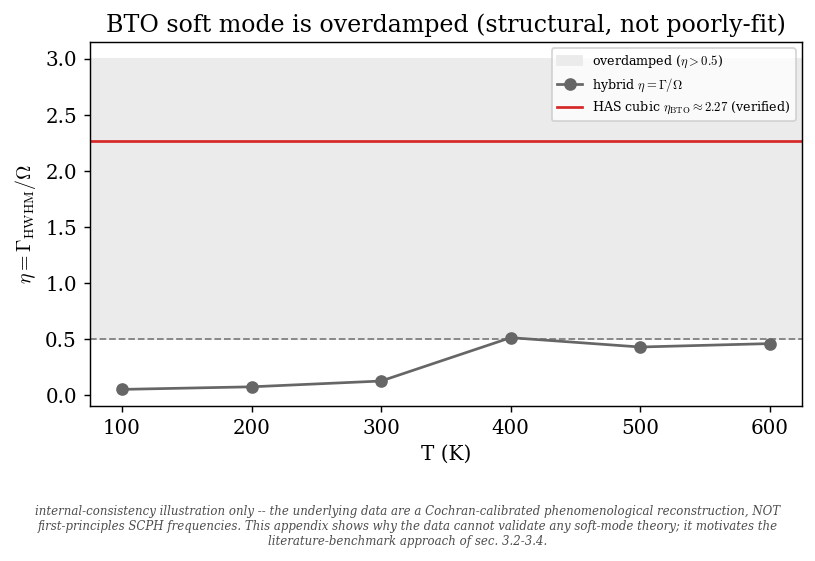

In [4]:
# Why this is a STRUCTURAL failure, not a poor fit: BTO's soft mode is genuinely
# OVERDAMPED -- outside the underdamped-quasiparticle framework the residual assumes.
# Independent confirmation: HAS 1971 cubic-phase eta_BTO ~ 2.27 (Turn-4B, verified vs
# figures); and even this hybrid reconstruction's own eta = Gamma/Omega crosses 0.5 at
# the 400 K dip -- the same temperature where delta blows up.
ETA_BTO_HAS = 2.27   # NB 06 / kappa_kernel MATERIALS (HAS Table I, Gamma/Omega cubic)
print(hyb[["T_K", "omega_meV", "gamma_hwhm_meV", "eta"]].round(3).to_string(index=False))
print(f"\nhybrid eta max = {hyb['eta'].max():.2f} (at {int(hyb.loc[hyb['eta'].idxmax(),'T_K'])} K); "
      f"HAS-verified cubic eta_BTO = {ETA_BTO_HAS}")

flag("hybrid eta crosses 0.5 at the 400 K dip", hyb["eta"].max() > 0.5,
     f"eta_max={hyb['eta'].max():.2f} -- not underdamped even in the reconstruction")
flag("HAS-verified eta_BTO overdamped (>0.5)", ETA_BTO_HAS > 0.5,
     "kernel overdamped guard + this appendix agree: BTO outside underdamped-QP framework")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.axhspan(0.5, 3.0, color="0.92", label=r"overdamped ($\eta>0.5$)")
ax.axhline(0.5, ls="--", color="0.5", lw=1)
ax.plot(hyb["T_K"], hyb["eta"], "-o", color="0.4", label=r"hybrid $\eta=\Gamma/\Omega$")
ax.axhline(ETA_BTO_HAS, color="tab:red", lw=1.5, label=r"HAS cubic $\eta_{\rm BTO}\approx2.27$ (verified)")
ax.set_xlabel("T (K)"); ax.set_ylabel(r"$\eta = \Gamma_{\rm HWHM}/\Omega$")
ax.set_title("BTO soft mode is overdamped (structural, not poorly-fit)")
ax.legend(fontsize=7); stamp(fig); fig.tight_layout()
fig.savefig(FIG_DIR / "fig_NB09_overdamping_context.pdf", bbox_inches="tight")
plt.show()


## 4. Gate / conclusion

> **internal-consistency illustration only; the underlying data are a Cochran-calibrated phenomenological reconstruction, not first-principles SCPH frequencies; this appendix demonstrates why the data cannot validate any soft-mode theory and motivates the literature-benchmark approach of §3.2–§3.4.**


In [5]:
n_stop = sum(1 for _, ok, _ in FLAGS if not ok)
print("\nNB 09 flags:")
for item, ok, note in FLAGS:
    print(f"  [{'OK ' if ok else 'STOP'}] {item}" + (f"  ({note})" if note else ""))
print()
if n_stop:
    print(f"NB 09 GATE: STOP FOR SIGN-OFF ({n_stop} flag(s) tripped).")
else:
    print("NB 09 GATE: PASS (negative result faithfully reproduced + fully disclaimed).")
    print("The hybrid BTO CSVs are a Cochran-calibrated reconstruction, not SCPH frequencies;")
    print("scalar-SCPH residual blows up (+2806% at 400 K) because the datasets are")
    print("incommensurate, and BTO's soft mode is genuinely overdamped (eta_BTO~2.27, HAS) --")
    print("so the data cannot validate any soft-mode theory. This motivates the")
    print("literature-benchmark approach of sec. 3.2-3.4. STOP for sign-off (planned).")



NB 09 flags:
  [OK ] hybrid CSVs loaded unchanged  (6 temperatures 100-600 K)
  [OK ] soft mode non-monotonic (reconstruction artifact)  (dips to 3.5 meV at 400 K then recovers)
  [OK ] SCPH converged at all T (arithmetic correct)  (the disagreement is structural, not a bug)
  [OK ] delta ~ +2806% at 400 K reproduced  (delta=+2806%)
  [OK ] residual blows up (data incommensurate w/ SCPH)  (Ehsan q=0 SCPH ~13x the hybrid q=0.1 reconstruction; Lambda^2 q^2 cannot bridge)
  [OK ] hybrid eta crosses 0.5 at the 400 K dip  (eta_max=0.51 -- not underdamped even in the reconstruction)
  [OK ] HAS-verified eta_BTO overdamped (>0.5)  (kernel overdamped guard + this appendix agree: BTO outside underdamped-QP framework)

NB 09 GATE: PASS (negative result faithfully reproduced + fully disclaimed).
The hybrid BTO CSVs are a Cochran-calibrated reconstruction, not SCPH frequencies;
scalar-SCPH residual blows up (+2806% at 400 K) because the datasets are
incommensurate, and BTO's soft mode is genuinel